In [22]:
import pandas as pd
df = pd.read_csv("cleaned_all_egypt.csv")
print(df.shape)

(47420, 25)


In [23]:
df.columns.tolist()

['id',
 'title',
 'price',
 'price_period',
 'property_type',
 'latitude',
 'longitude',
 'share_url',
 'bedrooms',
 'bathrooms',
 'size',
 'amenities',
 'category',
 'listing_count',
 'size_source',
 'period_source',
 'price_unit_fixed',
 'region',
 'city',
 'district',
 'compound',
 'value_per_sqm',
 'distance_to_center_km',
 'market_sector',
 'amenity_rank']

In [24]:
df.head()

,id,title,price,price_period,property_type,latitude,longitude,share_url,bedrooms,bathrooms,...,period_source,price_unit_fixed,region,city,district,compound,value_per_sqm,distance_to_center_km,market_sector,amenity_rank
0,52974566,Luxurious Living in the Heart of Hyde Park!,50000.0,monthly,Apartment,29.995922,31.554127,https://www.propertyfinder.eg/en/plp/rent/apar...,3,3,...,original,False,Cairo,New Cairo City,Hyde Park,Hyde Park,265.0,31.1,Residential,4
1,8653638,Apartment for Rent in Al Marasem Compound,35000.0,monthly,Apartment,30.051462,31.538992,https://www.propertyfinder.eg/en/plp/rent/apar...,3,2,...,original,False,Cairo,New Cairo City,The 5th Settlement,Moon Residences,206.0,29.2,Residential,5
2,52974180,Flat Ultra Super Lux First Use For Rent-Villette,70000.0,monthly,Apartment,30.022596,31.545815,https://www.propertyfinder.eg/en/plp/rent/apar...,3,3,...,original,False,Cairo,New Cairo City,The 5th Settlement,Villette,435.0,30.0,Residential,8
3,52969227,Studio for Rent — South Lotus (New Cairo),22000.0,monthly,Apartment,30.019306,31.513653,https://www.propertyfinder.eg/en/plp/rent/apar...,1,1,...,original,False,Cairo,New Cairo City,El Lotus,South Lotus,275.0,26.9,Residential,11
4,52969105,Studio for Rent — Hyde Park New Cairo First Us,35000.0,monthly,Apartment,29.995922,31.554127,https://www.propertyfinder.eg/en/plp/rent/apar...,1,1,...,original,False,Cairo,New Cairo City,Hyde Park,Hyde Park,438.0,31.1,Residential,11


In [25]:
df["price_period"].value_counts()


price_period
sell       24602
monthly    22818
Name: count, dtype: int64

In [26]:
df["market_sector"].value_counts()

market_sector
Residential       30147
Administrative    11163
Commercial         4083
Medical            1607
Other               420
Name: count, dtype: int64

In [27]:
df.isna().sum()

id                         0
title                      0
price                      0
price_period               0
property_type              0
latitude                   0
longitude                  0
share_url                  0
bedrooms                   0
bathrooms                  0
size                       0
amenities                  0
category                   0
listing_count              0
size_source                0
period_source              0
price_unit_fixed           0
region                     0
city                       0
district                 882
compound                 882
value_per_sqm              0
distance_to_center_km      0
market_sector              0
amenity_rank               0
dtype: int64

In [28]:
sales = df[(df["price_period"] == "sell") & (df["market_sector"] == "Residential")].copy()
print(sales.shape)
sales[["price", "size", "bedrooms", "bathrooms", "distance_to_center_km", "amenity_rank"]].describe()


(17483, 25)


,price,size,bedrooms,bathrooms,distance_to_center_km,amenity_rank
count,1.748300e+04,17483.000000,17483.000000,17483.000000,17483.000000,17483.000000
mean,1.619900e+07,208.970371,3.064119,2.974432,96.135863,10.168964
std,2.129117e+07,160.507207,1.121524,1.292077,129.991026,5.556405
min,5.000000e+05,21.000000,1.000000,1.000000,0.400000,0.000000
25%,6.000000e+06,125.000000,2.000000,2.000000,24.800000,5.000000
50%,1.040000e+07,171.000000,3.000000,3.000000,32.300000,9.000000
75%,1.850000e+07,242.000000,4.000000,4.000000,56.400000,16.000000
max,7.500000e+08,2500.000000,7.000000,7.000000,603.300000,18.000000


In [29]:
df.head()

,id,title,price,price_period,property_type,latitude,longitude,share_url,bedrooms,bathrooms,...,period_source,price_unit_fixed,region,city,district,compound,value_per_sqm,distance_to_center_km,market_sector,amenity_rank
0,52974566,Luxurious Living in the Heart of Hyde Park!,50000.0,monthly,Apartment,29.995922,31.554127,https://www.propertyfinder.eg/en/plp/rent/apar...,3,3,...,original,False,Cairo,New Cairo City,Hyde Park,Hyde Park,265.0,31.1,Residential,4
1,8653638,Apartment for Rent in Al Marasem Compound,35000.0,monthly,Apartment,30.051462,31.538992,https://www.propertyfinder.eg/en/plp/rent/apar...,3,2,...,original,False,Cairo,New Cairo City,The 5th Settlement,Moon Residences,206.0,29.2,Residential,5
2,52974180,Flat Ultra Super Lux First Use For Rent-Villette,70000.0,monthly,Apartment,30.022596,31.545815,https://www.propertyfinder.eg/en/plp/rent/apar...,3,3,...,original,False,Cairo,New Cairo City,The 5th Settlement,Villette,435.0,30.0,Residential,8
3,52969227,Studio for Rent — South Lotus (New Cairo),22000.0,monthly,Apartment,30.019306,31.513653,https://www.propertyfinder.eg/en/plp/rent/apar...,1,1,...,original,False,Cairo,New Cairo City,El Lotus,South Lotus,275.0,26.9,Residential,11
4,52969105,Studio for Rent — Hyde Park New Cairo First Us,35000.0,monthly,Apartment,29.995922,31.554127,https://www.propertyfinder.eg/en/plp/rent/apar...,1,1,...,original,False,Cairo,New Cairo City,Hyde Park,Hyde Park,438.0,31.1,Residential,11


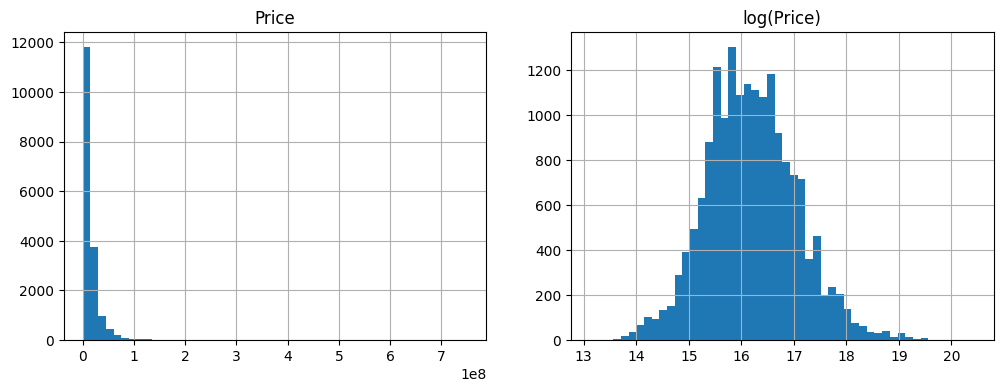

In [30]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sales["price"].hist(bins=50, ax=ax[0])
ax[0].set_title("Price")
np.log(sales["price"]).hist(bins=50, ax=ax[1])
ax[1].set_title("log(Price)")
plt.show()

In [31]:
sales.nlargest(10, "price")[["price", "size", "property_type", "region", "city"]]

,price,size,property_type,region,city
24257,750000000.0,1800.0,Villa,Cairo,New Cairo City
27352,352000000.0,2200.0,Villa,Cairo,New Cairo City
25747,310000000.0,700.0,Villa,Cairo,New Cairo City
26517,308000000.0,1280.0,Villa,Cairo,New Cairo City
5209,305000000.0,1150.0,Villa,Cairo,New Cairo City
17187,305000000.0,1200.0,Villa,Cairo,New Cairo City
26994,303420000.0,1632.0,Villa,Cairo,New Cairo City
17465,290000000.0,1600.0,Villa,Cairo,New Cairo City
17213,281000000.0,1600.0,Villa,Cairo,New Cairo City
19757,280000000.0,1600.0,Villa,Giza,Sheikh Zayed City


In [32]:
sales["price"].quantile([0.01, 0.05, 0.95, 0.99, 0.995])

0.010      1500000.0
0.050      2805300.0
0.950     47000000.0
0.990    100000000.0
0.995    141000531.0
Name: price, dtype: float64

In [33]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

model_df = sales.copy()
model_df["log_price"] = np.log(model_df["price"])

num_cols = ["size", "bedrooms", "bathrooms", "distance_to_center_km", "amenity_rank"]
cat_cols = ["property_type", "region", "city"]

X = model_df[num_cols + cat_cols]
y = model_df["log_price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

pre = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), cat_cols)
], remainder="passthrough")

model = Pipeline([("pre", pre), ("lr", LinearRegression())])
model.fit(X_train, y_train)

pred = model.predict(X_test)
print("R2:", r2_score(y_test, pred))
print("MAE (log):", mean_absolute_error(y_test, pred))
print("MAE (EGP):", mean_absolute_error(np.exp(y_test), np.exp(pred)))

R2: 0.6155199325719198
MAE (log): 0.40409412558954594
MAE (EGP): 7247192.831039421


In [34]:
sales["property_type"].value_counts()

property_type
Apartment          8857
Villa              3130
Chalet             1812
Townhouse          1350
Twin House          822
Duplex              578
Penthouse           529
iVilla              241
Hotel Apartment     130
Cabin                23
Roof                  6
Palace                5
Name: count, dtype: int64

In [35]:
sales.groupby("region")["value_per_sqm"].agg(["median", "count"]).sort_values("median", ascending=False).head(10)

,median,count
region,,
North Coast,108333.0,1542
Red Sea,93750.0,1635
Suez,69543.5,764
Cairo,61538.0,8504
Giza,60000.0,4651
Demyat,48300.0,11
South Sainai,46221.0,48
Matrouh,42326.0,5
Alexandria,42250.0,275


In [36]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score

model_df = sales.copy()
model_df["log_price"] = np.log(model_df["price"])
for c in ["district", "compound"]:
    model_df[c] = model_df[c].fillna("Unknown")

num_cols = ["size", "bedrooms", "bathrooms", "distance_to_center_km",
            "amenity_rank", "latitude", "longitude"]
cat_cols = ["property_type", "region", "city", "district", "compound"]

X = model_df[num_cols + cat_cols]
y = model_df["log_price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

def make_pre():
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20, sparse_output=False), cat_cols)
    ], remainder="passthrough")

models = {
    "RandomForest": RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42),
    "HistGB": HistGradientBoostingRegressor(random_state=42),
}

for name, m in models.items():
    pipe = Pipeline([("pre", make_pre()), ("m", m)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    mape = np.median(np.abs(np.exp(pred) - np.exp(y_test)) / np.exp(y_test)) * 100
    print(f"{name}: R2={r2_score(y_test, pred):.3f} | MAE(log)={mean_absolute_error(y_test, pred):.3f} | median % error={mape:.1f}%")

RandomForest: R2=0.796 | MAE(log)=0.264 | median % error=17.5%
HistGB: R2=0.782 | MAE(log)=0.285 | median % error=20.0%


<Axes: title={'center': 'Feature importance'}>

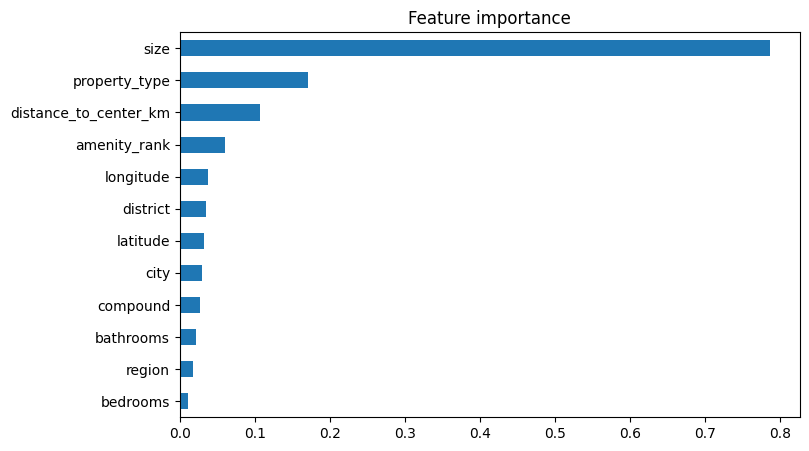

In [37]:
from sklearn.inspection import permutation_importance
import pandas as pd

rf = Pipeline([("pre", make_pre()), ("m", RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42))])
rf.fit(X_train, y_train)

r = permutation_importance(rf, X_test, y_test, n_repeats=5, random_state=42, n_jobs=-1)
imp = pd.Series(r.importances_mean, index=X_test.columns).sort_values()
imp.plot(kind="barh", figsize=(8, 5), title="Feature importance")

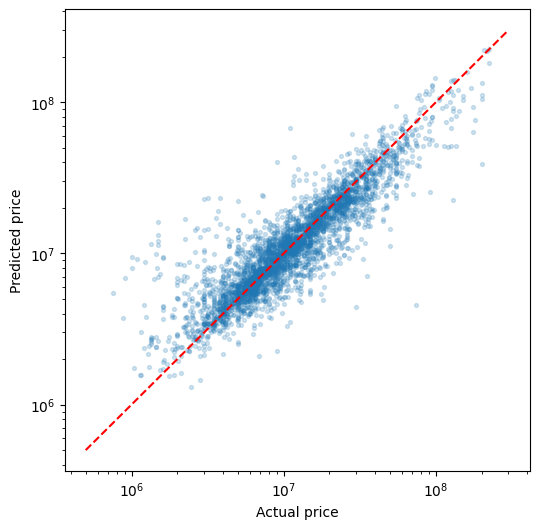

In [38]:
import matplotlib.pyplot as plt

pred = rf.predict(X_test)
plt.figure(figsize=(6, 6))
plt.scatter(np.exp(y_test), np.exp(pred), alpha=0.2, s=8)
lim = [5e5, 3e8]
plt.plot(lim, lim, "r--")
plt.xscale("log"); plt.yscale("log")
plt.xlabel("Actual price"); plt.ylabel("Predicted price")
plt.show()

In [39]:
rng = np.random.default_rng(42)
loc_cols = ["latitude", "longitude", "district", "city", "compound", "region", "distance_to_center_km"]

base = r2_score(y_test, rf.predict(X_test))
scores = []
for _ in range(5):
    Xp = X_test.copy()
    idx = rng.permutation(len(Xp))
    Xp[loc_cols] = Xp[loc_cols].iloc[idx].values
    scores.append(base - r2_score(y_test, rf.predict(Xp)))

print("Location group importance (drop in R2):", np.mean(scores))

Location group importance (drop in R2): 0.36478925137096596


In [40]:
sales["region"].value_counts(normalize=True) * 100


region
Cairo           48.641537
Giza            26.602986
Red Sea          9.351942
North Coast      8.819997
Suez             4.369959
Alexandria       1.572957
South Sainai     0.274552
Qalyubia         0.245953
Demyat           0.062918
Matrouh          0.028599
Al Daqahlya      0.017160
Sharqia          0.011440
Name: proportion, dtype: float64

In [41]:
pct = sales["region"].isin(["Cairo", "Giza"]).mean() * 100
print(f"Cairo + Giza: {pct:.1f}%")

Cairo + Giza: 75.2%
